## Interval Analysis

In [1]:
# !pip install tensorboardX

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
import time
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
# from tensorboardX import SummaryWriter

use_cuda = False
device = torch.device("cuda" if use_cuda else "cpu")
batch_size = 64

np.random.seed(42)
torch.manual_seed(42)


## Dataloaders
train_dataset = datasets.MNIST('mnist_data/', train=True, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))
test_dataset = datasets.MNIST('mnist_data/', train=False, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

## Simple NN. You can change this if you want. If you change it, mention the architectural details in your report.
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.fc = nn.Linear(28*28, 200)
        self.fc2 = nn.Linear(200,10)

    def forward(self, x):
        x = x.view((-1, 28*28))
        x = F.relu(self.fc(x))
        x = self.fc2(x)
        x = F.softmax(x, dim=-1) # added softmax for probabilities
        return x

class Normalize(nn.Module):
    def forward(self, x):
        return (x - 0.1307)/0.3081

# Add the data normalization as a first "layer" to the network
# this allows us to search for adverserial examples to the real image, rather than
# to the normalized image
model = nn.Sequential(Normalize(), Net())

model = model.to(device)
model.train()


100%|██████████| 9.91M/9.91M [00:00<00:00, 54.2MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.70MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 15.4MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.77MB/s]


Sequential(
  (0): Normalize()
  (1): Net(
    (fc): Linear(in_features=784, out_features=200, bias=True)
    (fc2): Linear(in_features=200, out_features=10, bias=True)
  )
)

In [2]:
def train_model(model, num_epochs):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9)

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        for i, data in enumerate(train_loader, 0):
            images, labels = data
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        print(f'Epoch {epoch+1}/{num_epochs}, Loss: {running_loss/len(train_loader):.3f}')

def test_model(model):
    model.eval()
    with torch.no_grad():
        correct = 0
        total = 0
        for data in test_loader:
            images, labels = data
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
        print(f'Accuracy on images: {100 * correct / total}')

In [3]:
train_model(model, 15)
test_model(model)

Epoch 1/15, Loss: 2.012
Epoch 2/15, Loss: 1.729
Epoch 3/15, Loss: 1.627
Epoch 4/15, Loss: 1.596
Epoch 5/15, Loss: 1.582
Epoch 6/15, Loss: 1.572
Epoch 7/15, Loss: 1.566
Epoch 8/15, Loss: 1.561
Epoch 9/15, Loss: 1.557
Epoch 10/15, Loss: 1.553
Epoch 11/15, Loss: 1.550
Epoch 12/15, Loss: 1.547
Epoch 13/15, Loss: 1.545
Epoch 14/15, Loss: 1.542
Epoch 15/15, Loss: 1.540
Accuracy on images: 93.43


### Write the interval analysis for the simple model

The network is used exactly as given (including the final softmax). Softmax is increasing and keeps the order of the outputs, so $\arg\max_j \mathrm{softmax}(z)_j = \arg\max_j z_j$. We therefore analyse the outputs $f(x)$ of the last linear layer (the inputs of the softmax): $f_y(x') \ge f_j(x')$ for all $j$ exactly when the softmax output predicts $y$.

For an image $x$ with label $y$ and radius $\epsilon$, the input region is the box $[\max(x-\epsilon,0),\ \min(x+\epsilon,1)]$. We push lower/upper bounds through each layer:
* Normalize and ReLU are increasing, so we apply them to both bounds.
* Linear layer: positive weights map lower to lower, negative weights swap the bounds.
* Extra output layer: $f_y - f_j$ for every $j \neq y$ (weights $W_y - W_j$, bias $b_y - b_j$).

The image is **verified** if the lower bound of every $f_y - f_j$ is not negative.

In [4]:
## TODO: Write the interval analysis for the simple model
## you can use https://github.com/Zinoex/bound_propagation

def interval_analysis(model, image, label, eps):
    net = model[1]
    x = image.view(-1)

    l = torch.clamp(x - eps, 0, 1)
    u = torch.clamp(x + eps, 0, 1)

    l = (l - 0.1307) / 0.3081
    u = (u - 0.1307) / 0.3081

    W, b = net.fc.weight, net.fc.bias
    W_pos, W_neg = W.clamp(min=0), W.clamp(max=0)
    new_l = W_pos @ l + W_neg @ u + b
    new_u = W_pos @ u + W_neg @ l + b
    l, u = new_l, new_u

    l, u = l.clamp(min=0), u.clamp(min=0)

    W, b = net.fc2.weight, net.fc2.bias
    for j in range(10):
        if j == label:
            continue
        w = W[label] - W[j]
        c = b[label] - b[j]
        lower = w.clamp(min=0) @ l + w.clamp(max=0) @ u + c
        if lower < 0:
            return False
    return True

### Sanity check
With $\epsilon = 0$ the box is a single image, so "verified" must be the same as "correctly classified".

In [5]:
model.eval()
with torch.no_grad():
    same = 0
    for i in range(1000):
        image, label = test_dataset[i]
        pred = model(image).argmax().item()
        same += (interval_analysis(model, image, label, 0.0) == (pred == label))
print(f"eps = 0: verified agrees with correct prediction on {same}/1000 images")

eps = 0: verified agrees with correct prediction on 1000/1000 images


### Verified accuracy on the whole test set for 10 values of $\epsilon$ in $[0.01, 0.1]$

In [6]:
model.eval()
epsilons = np.linspace(0.01, 0.1, 10)
verified_acc = []

with torch.no_grad():
    for eps in epsilons:
        start = time.time()
        verified = 0
        for image, label in test_dataset:
            if interval_analysis(model, image, label, eps):
                verified += 1
        acc = 100 * verified / len(test_dataset)
        verified_acc.append(acc)
        print(f"eps = {eps:.2f}   verified accuracy = {acc:.2f}%   time = {time.time() - start:.1f}s")

eps = 0.01   verified accuracy = 70.55%   time = 10.0s
eps = 0.02   verified accuracy = 23.68%   time = 7.5s
eps = 0.03   verified accuracy = 4.56%   time = 7.1s
eps = 0.04   verified accuracy = 0.58%   time = 5.8s
eps = 0.05   verified accuracy = 0.02%   time = 6.4s
eps = 0.06   verified accuracy = 0.00%   time = 5.4s
eps = 0.07   verified accuracy = 0.00%   time = 6.4s
eps = 0.08   verified accuracy = 0.00%   time = 5.4s
eps = 0.09   verified accuracy = 0.00%   time = 5.8s
eps = 0.10   verified accuracy = 0.00%   time = 5.9s


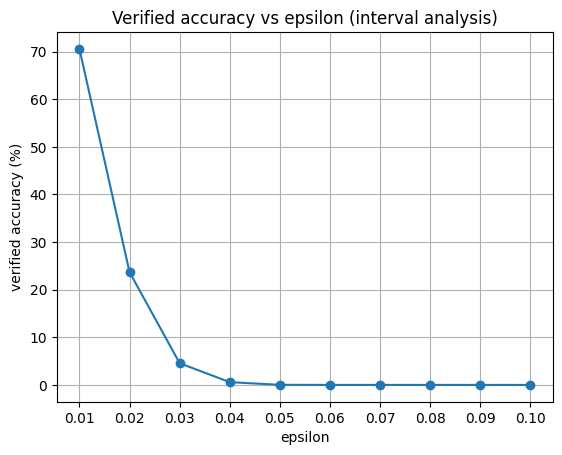

In [7]:
plt.plot(epsilons, verified_acc, 'o-')
plt.xlabel("epsilon")
plt.ylabel("verified accuracy (%)")
plt.title("Verified accuracy vs epsilon (interval analysis)")
plt.xticks(epsilons)
plt.grid(True)
plt.show()

### Example images

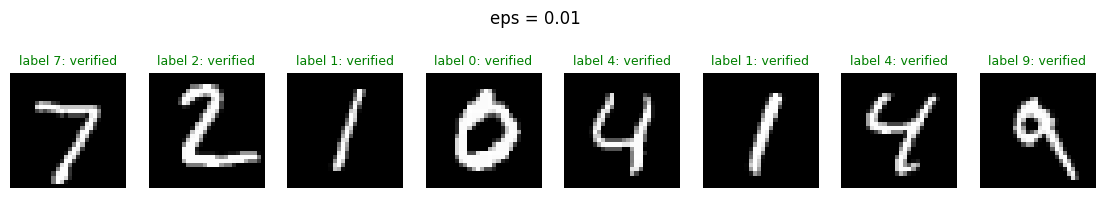

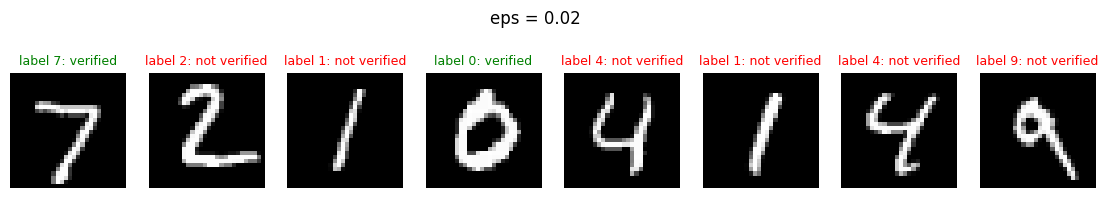

In [8]:
for eps in [0.01, 0.02]:
    fig, axes = plt.subplots(1, 8, figsize=(14, 2.5))
    with torch.no_grad():
        for i in range(8):
            image, label = test_dataset[i]
            ok = interval_analysis(model, image, label, eps)
            axes[i].imshow(image[0], cmap='gray')
            axes[i].set_title(f"label {label}: {'verified' if ok else 'not verified'}",
                              color='green' if ok else 'red', fontsize=9)
            axes[i].axis('off')
    fig.suptitle(f"eps = {eps}")
    plt.show()

### Observations

1. Verified accuracy drops as $\epsilon$ grows.
2. The bounds are loose because intervals treat every neuron independently.